In [ ]:

import torch
import torch.nn.functional as F
import gpytorch
import matplotlib.pyplot as plt
import time
import numpy as np

# Set random seeds so outputs are traceable
torch.manual_seed(42)
np.random.seed(42)

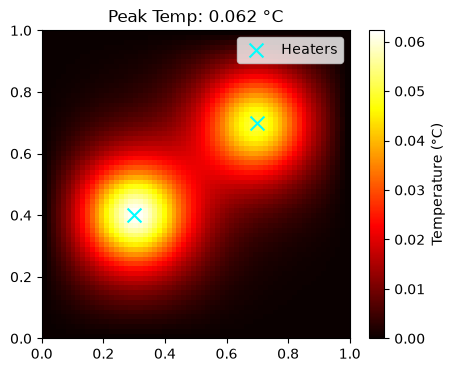

In [ ]:
def simulate_heat(sources, grid_size=32, steps=100):
    """
    Simulates heat on a metal plate.
    sources: tensor of shape (2, 3) -> [[x1, y1, power1], [x2, y2, power2]]
    grid_size: width/height in pixels
    steps: how many times averaging blur is run
    """
    dx = 1.0 / (grid_size - 1)
    
    # 1. Create a 2D coordinate grid (from 0.0 to 1.0)
    x = torch.linspace(0.0, 1.0, grid_size)
    y = torch.linspace(0.0, 1.0, grid_size)
    grid_y, grid_x = torch.meshgrid(y, x, indexing="ij")
    
    # 2. Inject heat from each heater as a glowing circle
    Q = torch.zeros((1, 1, grid_size, grid_size))
    for src in sources:
        sx, sy, power = src[0], src[1], src[2]
        dist_sq = (grid_x - sx)**2 + (grid_y - sy)**2
        Q += power * torch.exp(-dist_sq / (2 * 0.08**2))
    
    # 3. 4-neighbor averaging filter: [Top, Bottom, Left, Right]
    stencil = torch.tensor([
        [0.00, 0.25, 0.00],
        [0.25, 0.00, 0.25],
        [0.00, 0.25, 0.00]
    ]).view(1, 1, 3, 3)
    
    # 4. An initial cold plate (all zeros)
    T = torch.zeros((1, 1, grid_size, grid_size))
    q_term = 0.25 * (dx ** 2) * Q
    
    # 5. Run the diffusion blur loop
    for _ in range(steps):
        T = F.conv2d(T, stencil, padding=1) + q_term
        # Keep border cold (Dirichlet boundary)
        T[:, :, 0, :] = 0.0
        T[:, :, -1, :] = 0.0
        T[:, :, :, 0] = 0.0
        T[:, :, :, -1] = 0.0
        
    return T.squeeze() # return the 2D grid of temperatures

# testing a simulation
example_heaters = torch.tensor([
    [0.3, 0.4, 10.0],  # Heater 1: x=0.3, y=0.4, power=10
    [0.7, 0.7, 8.0]    # Heater 2: x=0.7, y=0.7, power=8
])

temp_map = simulate_heat(example_heaters, grid_size=64, steps=300)

plt.figure(figsize=(5, 4))
plt.imshow(temp_map.numpy(), origin='lower', cmap='hot', extent=[0, 1, 0, 1])
plt.colorbar(label="Temperature (°C)")
plt.scatter([0.3, 0.7], [0.4, 0.7], color='cyan', marker='x', s=100, label='Heaters')
plt.title(f"Peak Temp: {temp_map.max().item():.3f} °C")
plt.legend()
plt.show()

In [ ]:
def get_peak_temperature(sources, fidelity=0):
    start = time.perf_counter()
    if fidelity == 0:
        # Fast, rough estimate model
        grid = simulate_heat(sources, grid_size=16, steps=40)
    else:
        # Slow, accurate ground truth model
        grid = simulate_heat(sources, grid_size=64, steps=400)
    cost = time.perf_counter() - start
    peak_temp = grid.max().item()
    return peak_temp, cost

# Test both speeds on the same heater configuration
peak_fast, cost_fast = get_peak_temperature(example_heaters, fidelity=0)
peak_slow, cost_slow = get_peak_temperature(example_heaters, fidelity=1)

print(f"Fast (Fidelity 0): {peak_fast:.4f} °C | Time: {cost_fast*1000:.2f} ms")
print(f"Slow (Fidelity 1): {peak_slow:.4f} °C | Time: {cost_slow*1000:.2f} ms")
#compute cost tradeoff based on time
print(f"The slow simulation is {cost_slow / cost_fast:.1f}x more expensive!")

Fast (Fidelity 0): 0.0890 °C | Time: 17.26 ms
Slow (Fidelity 1): 0.0706 °C | Time: 70.30 ms
The slow simulation is 4.1x more expensive!


In [24]:
def random_heater_setup():
    """Generates random positions and powers for 2 heaters"""
    return torch.tensor([
        [np.random.uniform(0.2, 0.4), np.random.uniform(0.2, 0.8), np.random.uniform(5.0, 15.0)],
        [np.random.uniform(0.6, 0.8), np.random.uniform(0.2, 0.8), np.random.uniform(5.0, 15.0)]
    ], dtype=torch.float32)

X_rows = []
y_rows = []

# Collect 8 fast runs
print("Generating 8 cheap samples...")
for _ in range(8):
    setup = random_heater_setup()
    peak, _ = get_peak_temperature(setup, fidelity=0)
    # Flatten the 6 heater features + append fidelity=0.0
    row = torch.cat([setup.flatten(), torch.tensor([0.0])])
    X_rows.append(row)
    y_rows.append(peak)

# Collect 2 slow runs
print("Generating 2 expensive samples...")
for _ in range(2):
    setup = random_heater_setup()
    peak, _ = get_peak_temperature(setup, fidelity=1)
    # Flatten the 6 heater features + append fidelity=1.0
    row = torch.cat([setup.flatten(), torch.tensor([1.0])])
    X_rows.append(row)
    y_rows.append(peak)

train_X = torch.stack(X_rows)
train_y = torch.tensor(y_rows, dtype=torch.float32)

print("\nDataset ready!")
print("Input shape (Features + Fidelity):", train_X.shape)
print("Target shape (Peak Temperatures):", train_y.shape)

Generating 8 cheap samples...
Generating 2 expensive samples...

Dataset ready!
Input shape (Features + Fidelity): torch.Size([10, 7])
Target shape (Peak Temperatures): torch.Size([10])


In [ ]:
class SimpleMultiFidelityGP(gpytorch.models.ExactGP):
    def __init__(self, train_x, train_y, likelihood):
        super().__init__(train_x, train_y, likelihood)
        self.mean_module = gpytorch.means.ConstantMean()
        
        # Spatial distance kernel on heater features (columns 0 through 5)
        self.spatial_kernel = gpytorch.kernels.MaternKernel(nu=2.5, active_dims=tuple(range(6)))
        
        # Task correlation kernel on fidelity index (column 6: 0 or 1)
        self.task_kernel = gpytorch.kernels.IndexKernel(num_tasks=2, rank=1, active_dims=(6,))
        
        # Combine: Spatial * Task
        self.covar_module = self.spatial_kernel * self.task_kernel

    def forward(self, x):
        mean = self.mean_module(x)
        covar = self.covar_module(x)
        return gpytorch.distributions.MultivariateNormal(mean, covar)

# Initialize likelihood and model
likelihood = gpytorch.likelihoods.GaussianLikelihood()
model = SimpleMultiFidelityGP(train_X, train_y, likelihood)

# Train the model with Adam optimizer
model.train()
likelihood.train()
optimizer = torch.optim.Adam(model.parameters(), lr=0.1)
mll = gpytorch.mlls.ExactMarginalLogLikelihood(likelihood, model)

print("Training Gaussian Process...")
for step in range(80):
    optimizer.zero_grad()
    output = model(train_X)
    loss = -mll(output, train_y)
    loss.backward()
    optimizer.step()
    if (step + 1) % 20 == 0:
        print(f"Step {step+1:02d}/80 - Loss: {loss.item():.4f}")

Training Gaussian Process...


C:\Users\Admin\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\linear_operator\utils\interpolation.py:66: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:823.)
  summing_matrix = torch.sparse_coo_tensor(


Step 20/80 - Loss: 0.2964
Step 40/80 - Loss: -0.7752
Step 60/80 - Loss: -1.8232
Step 80/80 - Loss: -2.3780


In [ ]:
# Create a new test setup
new_test_setup = random_heater_setup()

# predict what the slow, accurate simulation (fidelity=1.0) would yield:
test_input = torch.cat([new_test_setup.flatten(), torch.tensor([1.0])]).unsqueeze(0)

# Switch model to evaluation mode
model.eval()
likelihood.eval()

with torch.no_grad():
    prediction_dist = likelihood(model(test_input))
    pred_mean = prediction_dist.mean.item()
    pred_std = prediction_dist.stddev.item()

# run the actual simulation to see how close our guess was
actual_temp, _ = get_peak_temperature(new_test_setup, fidelity=1)

print("=" * 45)
print(f"AI Prediction: {pred_mean:.4f} °C ± {2*pred_std:.4f} °C (95% confidence)")
print(f"Actual Answer: {actual_temp:.4f} °C")
print(f"Absolute Error: {abs(pred_mean - actual_temp):.4f} °C")
print("=" * 45)

AI Prediction: 0.0950 °C ± 0.0514 °C (95% confidence)
Actual Answer: 0.1026 °C
Absolute Error: 0.0076 °C


In [ ]:
# Generate 10 candidate heater setups to run next
candidates = [random_heater_setup().flatten() for _ in range(10)]
cand_tensor = torch.stack(candidates)

# Check uncertainty for both Fast (cost = 1) and Slow (cost = 30)
with torch.no_grad():
    cand_low = torch.cat([cand_tensor, torch.zeros(10, 1)], dim=-1)
    cand_high = torch.cat([cand_tensor, torch.ones(10, 1)], dim=-1)
    
    uncert_low = likelihood(model(cand_low)).variance
    uncert_high = likelihood(model(cand_high)).variance

# Value per compute cost
cost_low = 1.0
cost_high = 30.0

value_low = uncert_low / cost_low
value_high = uncert_high / cost_high

print("Candidate Evaluation (Variance / Cost):")
print(f"Highest value in cheap run: {value_low.max().item():.5f}")
print(f"Highest value in slow run:  {value_high.max().item():.5f}")

if value_low.max() > value_high.max():
    print("\nDecision: Run a CHEAP simulation on the most uncertain candidate!")
else:
    print("\nDecision: Run an EXPENSIVE simulation on the most uncertain candidate!")

Candidate Evaluation (Variance / Cost):
Highest value in cheap run: 0.00058
Highest value in slow run:  0.00005

Decision: Run a CHEAP simulation on the most uncertain candidate!


In [46]:
# Automated Active Learning Loop 
print("Starting Active Learning Loop...\n")

total_time_spent = 0.0

for loop_iter in range(1, 6):
    # 1. Generate 20 random candidates to query
    candidates = [random_heater_setup().flatten() for _ in range(20)]
    cand_tensor = torch.stack(candidates)
    
    # 2. Score candidates on both fidelities
    model.eval()
    likelihood.eval()
    with torch.no_grad():
        c_low = torch.cat([cand_tensor, torch.zeros(20, 1)], dim=-1)
        c_high = torch.cat([cand_tensor, torch.ones(20, 1)], dim=-1)
        
        # Variance / Cost
        val_low = likelihood(model(c_low)).variance / 17.0   # Fast cost ~17ms
        val_high = likelihood(model(c_high)).variance / 70.0 # Slow cost ~70ms
    
    max_val_low, idx_low = val_low.max(dim=0)
    max_val_high, idx_high = val_high.max(dim=0)
    
    # Choose fidelity with highest return on investment
    if max_val_low >= max_val_high:
        chosen_fidelity = 0
        chosen_setup = candidates[idx_low]
    else:
        chosen_fidelity = 1
        chosen_setup = candidates[idx_high]
        
    # 3. Query the physical simulation
    sources = chosen_setup.view(2, 3)
    new_temp, runtime = get_peak_temperature(sources, fidelity=chosen_fidelity)
    total_time_spent += runtime
    
    fid_name = "CHEAP (Fidelity 0)" if chosen_fidelity == 0 else "SLOW  (Fidelity 1)"
    print(f"Iter {loop_iter}: AI queried {fid_name} | Sim time: {runtime*1000:.1f} ms | New Temp: {new_temp:.4f} °C")
    
    # 4. Append the new data to training set
    new_x = torch.cat([chosen_setup, torch.tensor([float(chosen_fidelity)])]).unsqueeze(0)
    train_X = torch.cat([train_X, new_x], dim=0)
    train_y = torch.cat([train_y, torch.tensor([new_temp])], dim=0)
    
    # 5. Retrain the model on the updated dataset
    model = SimpleMultiFidelityGP(train_X, train_y, likelihood)
    model.train()
    likelihood.train()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.08)
    mll = gpytorch.mlls.ExactMarginalLogLikelihood(likelihood, model)
    
    for _ in range(40):
        optimizer.zero_grad()
        loss = -mll(model(train_X), train_y)
        loss.backward()
        optimizer.step()

print(f"\nActive Learning complete! Total compute spent: {total_time_spent*1000:.1f} ms")
print(f"Total dataset size now: {len(train_X)} samples")

Starting Active Learning Loop...

Iter 1: AI queried SLOW  (Fidelity 1) | Sim time: 39.6 ms | New Temp: 0.1044 °C
Iter 2: AI queried SLOW  (Fidelity 1) | Sim time: 40.9 ms | New Temp: 0.0901 °C
Iter 3: AI queried CHEAP (Fidelity 0) | Sim time: 3.7 ms | New Temp: 0.0946 °C
Iter 4: AI queried CHEAP (Fidelity 0) | Sim time: 2.7 ms | New Temp: 0.1194 °C
Iter 5: AI queried CHEAP (Fidelity 0) | Sim time: 4.9 ms | New Temp: 0.1328 °C

Active Learning complete! Total compute spent: 91.8 ms
Total dataset size now: 45 samples
